# Solutions to the exercises of Chapter 11

Sample solutions for [Chapter 11, Heat exchangers](../../notebooks/part2_convection/11_heat_exchangers.ipynb).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import brentq

try:
    from engtransport import exchangers, reference
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    from engtransport import exchangers, reference
from engtransport.plotting import use_style

use_style()

# the substation of Section 11.4
Q, T_ps, T_ss, T_sr, T_pr = 400e3, 110.0, 70.0, 50.0, 55.0
C_p, C_s = Q / (T_ps - T_pr), Q / (T_ss - T_sr)
Cr = C_p / C_s
eps = Q / (C_p * (T_ps - T_sr))
NTU_cf = exchangers.ntu_from_effectiveness(eps, Cr, "counterflow")
UA = NTU_cf * C_p


def series(eps1, Cr, N):
    """Effectiveness of N identical units in series, connected in overall counterflow."""
    z = ((1 - eps1 * Cr) / (1 - eps1)) ** N
    return (z - 1) / (z - Cr)

## Exercise 1. Two exchangers in series

Each parallel-flow unit has $\mathrm{NTU}/N$; the formula of Exercise 3 combines them.

In [2]:
results = {}
for N in (1, 2, 3, 5, 10, 50):
    f = lambda NTU: series(exchangers.effectiveness_from_ntu(NTU / N, Cr, "parallel"), Cr, N) - eps
    try:
        NTU_N = brentq(f, 0.1, 200.0)
        results[N] = NTU_N
        print(f"{N:2d} parallel-flow units: total NTU = {NTU_N:6.3f}, UA = {NTU_N * C_p / 1e3:6.1f} kW/K ({NTU_N / NTU_cf:.2f} times counterflow)")
    except ValueError:
        print(f"{N:2d} parallel-flow units: cannot reach eps = {eps:.3f}")
print(f"single counterflow unit: NTU = {NTU_cf:.3f}")

 1 parallel-flow units: cannot reach eps = 0.917
 2 parallel-flow units: cannot reach eps = 0.917
 3 parallel-flow units: total NTU =  3.942, UA =   28.7 kW/K (1.21 times counterflow)
 5 parallel-flow units: total NTU =  3.456, UA =   25.1 kW/K (1.06 times counterflow)
10 parallel-flow units: total NTU =  3.311, UA =   24.1 kW/K (1.01 times counterflow)
50 parallel-flow units: total NTU =  3.269, UA =   23.8 kW/K (1.00 times counterflow)
single counterflow unit: NTU = 3.268


A single parallel-flow unit cannot reach the duty at all, and two in series cannot either:
each unit's outlets approach one temperature, and two such steps are not enough to lower
the primary water from 110 to 55 °C while raising the secondary from 50 to 70 °C. Three
units do it with 1.21 times the counterflow area, five with 1.06, and the penalty falls
towards zero
as the number of units grows: in the limit the chain becomes a counterflow exchanger,
because each short unit behaves like any other short unit, whatever its internal
arrangement.

## Exercise 2. Fouling in the substation

In [3]:
U_clean, R_f = 4000.0, 2e-4
U_dirty = 1 / (1 / U_clean + R_f)
UA_dirty = UA * U_dirty / U_clean
deficit = lambda C: exchangers.rate_exchanger(UA_dirty, C, C_s, T_ps, T_sr)["Q"] - Q
C_need = brentq(deficit, C_p, 50 * C_p)
r = exchangers.rate_exchanger(UA_dirty, C_need, C_s, T_ps, T_sr)
print(f"U falls from {U_clean:.0f} to {U_dirty:.0f} W/(m2 K); UA {UA / 1e3:.1f} -> {UA_dirty / 1e3:.1f} kW/K")
print(f"primary flow {C_need / C_p:.2f} times design, return {r['T_h_out']:.1f} C")

U falls from 4000 to 2222 W/(m2 K); UA 23.8 -> 13.2 kW/K
primary flow 1.46 times design, return 72.3 C


A fouling resistance of $2 \times 10^{-4}$ m² K/W, half the resistance of the clean plates,
cuts $U$ by 44 %. To keep 400 kW the substation must take 1.46 times its design primary
flow, and the water returns to the network at 72 °C instead of 55 °C. Because plate exchangers
have high clean coefficients, the same deposit hurts them more than it would hurt a
shell-and-tube unit with a lower $U$; Chapter 18 follows such a deposit over time.

## Exercise 3. Why not a shell-and-tube exchanger?

In [4]:
s = np.sqrt(1 + Cr**2)
eps_max_12 = 2 / (1 + Cr + s)
print(f"1-2 exchanger at Cr = {Cr:.3f}: largest eps = {eps_max_12:.3f} < {eps:.3f} needed;"
      f" lowest primary return {T_ps - eps_max_12 * (T_ps - T_sr):.1f} C")
for N in (2, 3, 4):
    eps_inf = series(eps_max_12, Cr, N)
    if eps_inf <= eps:
        print(f"{N} shells in series: at most eps = {eps_inf:.3f}, not enough")
        continue
    f = lambda NTU: series(exchangers.effectiveness_from_ntu(NTU / N, Cr, "shell_and_tube_1_2n"), Cr, N) - eps
    NTU_N = brentq(f, 0.5, 100.0)
    F = NTU_cf / NTU_N
    print(f"{N} shells in series: total NTU = {NTU_N:.3f} (F = {F:.3f}); largest possible eps = {eps_inf:.3f}")

1-2 exchanger at Cr = 0.364: largest eps = 0.824 < 0.917 needed; lowest primary return 60.6 C
2 shells in series: total NTU = 4.115 (F = 0.794); largest possible eps = 0.959
3 shells in series: total NTU = 3.547 (F = 0.921); largest possible eps = 0.990
4 shells in series: total NTU = 3.413 (F = 0.958); largest possible eps = 0.997


One 1-2 shell can reach an effectiveness of only 0.82 at this capacity ratio, so the
primary water could not leave colder than 61 °C however long the exchanger: in the
counter-current tube pass the outlet would have to be colder than the secondary outlet,
and the parallel pass undoes part of the work. This "temperature cross" is the usual
reason for using two or more shells in series. Two shells reach the duty with $F = 0.79$;
three bring $F$ to 0.92, close to counterflow. A plate exchanger in counterflow is the
simpler answer for clean water.

## Exercise 4. Protecting the coil

25 % flow, air at -35 C: coldest water at -10.9 C with 95 C water; 5 C needs water at 181 C
air at -35 C: the coldest water reaches 0 C at 32 % of the design flow
air at -25 C: the coldest water reaches 0 C at 27 % of the design flow


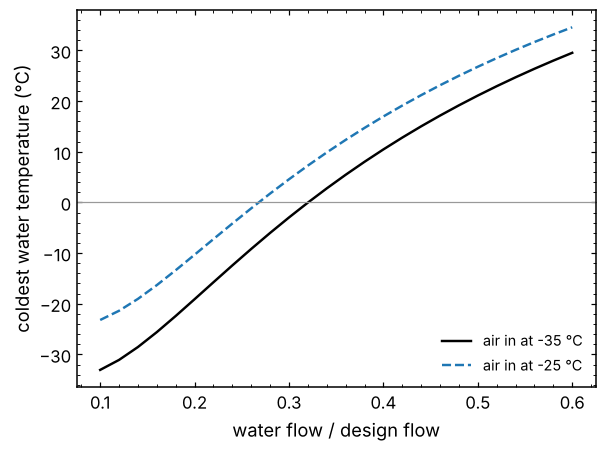

In [5]:
m_air, cp_air, T_wi, T_wo = 2.0, 1006.0, 95.0, 60.0
C_air = m_air * cp_air
Q_coil = C_air * 53.0
C_w = Q_coil / (T_wi - T_wo)
UA_c = exchangers.ntu_from_effectiveness(Q_coil / (C_air * 130.0), C_air / C_w, "crossflow_exact") * C_air


def coldest(fraction, T_wi, T_ai, n=100):
    Cw = fraction * C_w
    Cmin = min(Cw, C_air)
    r = reference.crossflow_cells(UA_c / Cmin, Cmin / max(Cw, C_air), n, "x" if Cw <= C_air else "y")
    return T_ai + (T_wi - T_ai) * r["Tx"][0, -1]


theta_min = (coldest(0.25, 1.0, 0.0))          # the coldest water as a fraction of (T_wi - T_ai)
T_wi_needed = -35.0 + (5.0 - (-35.0)) / theta_min
print(f"25 % flow, air at -35 C: coldest water at {coldest(0.25, 95.0, -35.0):.1f} C with 95 C water;"
      f" 5 C needs water at {T_wi_needed:.0f} C")
fracs = np.linspace(0.1, 0.6, 26)
for T_ai, style in ((-35.0, "k-"), (-25.0, "C0--")):
    f0 = brentq(lambda f: coldest(f, 95.0, T_ai), 0.05, 1.0)
    print(f"air at {T_ai:.0f} C: the coldest water reaches 0 C at {100 * f0:.0f} % of the design flow")
fig, ax = plt.subplots(figsize=(5.4, 4.0))
for T_ai, style in ((-35.0, "k-"), (-25.0, "C0--")):
    ax.plot(fracs, [coldest(f, 95.0, T_ai, n=60) for f in fracs], style, label=f"air in at {T_ai:.0f} °C")
ax.axhline(0.0, color="0.6", lw=0.8)
ax.set_xlabel("water flow / design flow")
ax.set_ylabel("coldest water temperature (°C)")
ax.legend(loc="lower right")
plt.show()

**Figure S11.1.** Coldest water temperature in the air-heating coil against the water flow,
for outdoor air at −35 and −25 °C (water in at 95 °C, design UA).

At 25 % flow the coldest water is at −11 °C; keeping it at 5 °C would need water at about
180 °C, far more than the network can supply, so in frost the flow itself must be kept up.
At −25 °C outdoors the coil tolerates throttling down to 27 % of the design flow instead of
32 %. Ventilation units in cold climates therefore combine a minimum valve opening with a
frost thermostat and, often, a pump that keeps water circulating through the coil.